In [1]:
import pandas as pd
from pathlib import Path 
RAW = Path(r"C:\Users\Suraksha Sanil\Downloads\cart2insights- data\Raw data")

In [6]:
customers = pd.read_csv(RAW / "olist_customers_dataset.csv")
Order_items = pd.read_csv(RAW /"olist_order_items_dataset.csv")
Order_Payments = pd.read_csv(RAW/"olist_order_payments_dataset.csv")
Order_reviews = pd.read_csv(RAW/"olist_order_reviews_dataset.csv")
Geolocation = pd.read_csv(RAW/"olist_geolocation_dataset.csv")
Order= pd.read_csv(RAW/"olist_orders_dataset.csv")
Products = pd.read_csv(RAW/"olist_products_dataset.csv")
Sellers = pd.read_csv(RAW/"olist_sellers_dataset.csv")
Category = pd.read_csv(RAW/"product_category_name_translation.csv")


Check the datashape 

In [7]:
tables = {"customers":customers,"Order_items":Order_items,"Order_Payments":Order_Payments,"Order_reviews":Order_reviews,"Geolocation":Geolocation,"Order":Order,"Products":Products,"Sellers":Sellers,"Category":Category}
for name,df in tables.items():
 print(f"{name:22} rows={df.shape[0]:>9,} columns={df.shape[1]}")

customers              rows=   99,441 columns=5
Order_items            rows=  112,650 columns=7
Order_Payments         rows=  103,886 columns=5
Order_reviews          rows=   99,224 columns=7
Geolocation            rows=1,000,163 columns=5
Order                  rows=   99,441 columns=8
Products               rows=   32,951 columns=9
Sellers                rows=    3,095 columns=4
Category               rows=       71 columns=2


In [8]:
for name, df in tables.items():
    print("=" * 50)
    print(name)
    df.info()

customers
<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 5 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   customer_id               99441 non-null  str  
 1   customer_unique_id        99441 non-null  str  
 2   customer_zip_code_prefix  99441 non-null  int64
 3   customer_city             99441 non-null  str  
 4   customer_state            99441 non-null  str  
dtypes: int64(1), str(4)
memory usage: 3.8 MB
Order_items
<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   order_id             112650 non-null  str    
 1   order_item_id        112650 non-null  int64  
 2   product_id           112650 non-null  str    
 3   seller_id            112650 non-null  str    
 4   shipping_limit_date  112650 non-null  str    
 5   pri

Identifying the missing Values

In [9]:
for name , df in tables.items ():
    missing = df.isna().sum()
    missing = missing [missing>0]
    if len (missing)>0:
     print(name)
     print(pd.DataFrame({"missing":missing, 
                         "percent":(missing/len(df)*100).round(2)}))

Order_reviews
                        missing  percent
review_comment_title      87656    88.34
review_comment_message    58247    58.70
Order
                               missing  percent
order_approved_at                  160     0.16
order_delivered_carrier_date      1783     1.79
order_delivered_customer_date     2965     2.98
Products
                            missing  percent
product_category_name           610     1.85
product_name_lenght             610     1.85
product_description_lenght      610     1.85
product_photos_qty              610     1.85
product_weight_g                  2     0.01
product_length_cm                 2     0.01
product_height_cm                 2     0.01
product_width_cm                  2     0.01


 Duplicates
 

In [10]:
for name, df in tables.items():
    print(name, df.duplicated().sum())

customers 0
Order_items 0
Order_Payments 0
Order_reviews 0
Geolocation 261831
Order 0
Products 0
Sellers 0
Category 0


In [11]:
Geolocation[Geolocation.duplicated()].head(10)

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng,geolocation_city,geolocation_state
15,1046,-23.546081,-46.644820,sao paulo,SP
44,1046,-23.546081,-46.644820,sao paulo,SP
65,1046,-23.546081,-46.644820,sao paulo,SP
66,1009,-23.546935,-46.636588,sao paulo,SP
67,1046,-23.546081,-46.644820,sao paulo,SP
72,1046,-23.545320,-46.644069,sao paulo,SP
79,1050,-23.549854,-46.643139,sao paulo,SP
80,1032,-23.540775,-46.635515,sao paulo,SP
82,1046,-23.546081,-46.644820,sao paulo,SP
86,1048,-23.547449,-46.640169,são paulo,SP


duplicates in the key columns

In [13]:
print("order_id:", Order["order_id"].duplicated().sum())
print("customer_id:", customers["customer_id"].duplicated().sum())
print("product_id:", Products["product_id"].duplicated().sum())
print("seller_id:", Sellers["seller_id"].duplicated().sum())
print("order_items (order_id, order_item_id):", Order_items.duplicated(["order_id", "order_item_id"]).sum())
print("payments (order_id, payment_sequential):", Order_Payments.duplicated(["order_id", "payment_sequential"]).sum())
print("review_id:", Order_reviews["review_id"].duplicated().sum())
print("reviews (review_id, order_id):", Order_reviews.duplicated(["review_id", "order_id"]).sum())
print("geolocation (zip prefix):", Geolocation["geolocation_zip_code_prefix"].duplicated().sum())
print("category (product_category_name):", Category["product_category_name"].duplicated().sum())

order_id: 0
customer_id: 0
product_id: 0
seller_id: 0
order_items (order_id, order_item_id): 0
payments (order_id, payment_sequential): 0
review_id: 814
reviews (review_id, order_id): 0
geolocation (zip prefix): 981148
category (product_category_name): 0


Summary Satistics 

In [14]:
Order_items[["price", "freight_value"]].describe()

,price,freight_value
count,112650.000000,112650.000000
mean,120.653739,19.990320
std,183.633928,15.806405
min,0.850000,0.000000
25%,39.900000,13.080000
50%,74.990000,16.260000
75%,134.900000,21.150000
max,6735.000000,409.680000


In [15]:
Order_Payments[["payment_installments", "payment_value"]].describe()

,payment_installments,payment_value
count,103886.000000,103886.000000
mean,2.853349,154.100380
std,2.687051,217.494064
min,0.000000,0.000000
25%,1.000000,56.790000
50%,1.000000,100.000000
75%,4.000000,171.837500
max,24.000000,13664.080000


In [18]:
Order_reviews["review_score"].describe()

count    99224.000000
mean         4.086421
std          1.347579
min          1.000000
25%          4.000000
50%          5.000000
75%          5.000000
max          5.000000
Name: review_score, dtype: float64

In [ ]:
Outliers

In [20]:
for df, c in [(Order_items, "price"), (Order_items, "freight_value"),
              (Order_Payments, "payment_value"), (Products, "product_weight_g")]:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    n = ((df[c] > q3 + 1.5 * iqr) | (df[c] < q1 - 1.5 * iqr)).sum()
    print(c, "outliers:", n, "| max:", df[c].max())

price outliers: 8427 | max: 6735.0
freight_value outliers: 12134 | max: 409.68
payment_value outliers: 7981 | max: 13664.08
product_weight_g outliers: 4551 | max: 40425.0


Data Cleaning -make copies and record starting row counts

In [21]:
customers_clean = customers.copy()
items_clean     = Order_items.copy()
payments_clean  = Order_Payments.copy()
reviews_clean   = Order_reviews.copy()
geo_clean       = Geolocation.copy()
orders_clean    = Order.copy()
products_clean  = Products.copy()
sellers_clean   = Sellers.copy()
category_clean  = Category.copy()
raw_rows = {name: len(df) for name, df in tables.items()}
raw_rows


{'customers': 99441,
 'Order_items': 112650,
 'Order_Payments': 103886,
 'Order_reviews': 99224,
 'Geolocation': 1000163,
 'Order': 99441,
 'Products': 32951,
 'Sellers': 3095,
 'Category': 71}

fixing the misspelled column names

In [22]:
products_clean = products_clean.rename(columns={
    "product_name_lenght": "product_name_length",
    "product_description_lenght": "product_description_length",
})
products_clean.columns.tolist()

['product_id',
 'product_category_name',
 'product_name_length',
 'product_description_length',
 'product_photos_qty',
 'product_weight_g',
 'product_length_cm',
 'product_height_cm',
 'product_width_cm']

In [23]:
order_date_cols = ["order_purchase_timestamp", "order_approved_at",
                   "order_delivered_carrier_date", "order_delivered_customer_date",
                   "order_estimated_delivery_date"]

for c in order_date_cols:
    orders_clean[c] = pd.to_datetime(orders_clean[c])

items_clean["shipping_limit_date"] = pd.to_datetime(items_clean["shipping_limit_date"])
reviews_clean["review_creation_date"] = pd.to_datetime(reviews_clean["review_creation_date"])
reviews_clean["review_answer_timestamp"] = pd.to_datetime(reviews_clean["review_answer_timestamp"])

orders_clean.dtypes

order_id                                    str
customer_id                                 str
order_status                                str
order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

In [24]:
orders_clean["order_delivered_customer_date"].isna().sum()

np.int64(2965)

In [25]:
customers_clean["customer_zip_code_prefix"] = (
    customers_clean["customer_zip_code_prefix"].astype(str).str.zfill(5))
sellers_clean["seller_zip_code_prefix"] = (
    sellers_clean["seller_zip_code_prefix"].astype(str).str.zfill(5))

customers_clean["customer_zip_code_prefix"].str.len().value_counts()

customer_zip_code_prefix
5    99441
Name: count, dtype: int64

In [26]:
# Products: no category -> label "unknown"
products_clean["product_category_name"] = products_clean["product_category_name"].fillna("unknown")

In [27]:
# A weight of 0 g is impossible, so treat it as missing first
products_clean["product_weight_g"] = products_clean["product_weight_g"].mask(
    products_clean["product_weight_g"] == 0)

In [28]:
# Fill weight and dimensions with the median
for c in ["product_weight_g", "product_length_cm", "product_height_cm", "product_width_cm"]:
    products_clean[c] = products_clean[c].fillna(products_clean[c].median())


In [29]:
# Reviews: the title is 88% empty and is not in the ER diagram
reviews_clean = reviews_clean.drop(columns=["review_comment_title"])


In [30]:
products_clean.isna().sum()[lambda s: s > 0]

product_name_length           610
product_description_length    610
product_photos_qty            610
dtype: int64

invalid values

In [31]:
# Removing the 3 "not_defined" payments (canceled orders, value 0)
payments_clean = payments_clean[payments_clean["payment_type"] != "not_defined"]



In [32]:
# A credit card payment has at least 1 installment
payments_clean.loc[payments_clean["payment_installments"] == 0, "payment_installments"] = 1


In [33]:
print(len(payments_clean))
print(payments_clean["payment_type"].unique().tolist())
print(payments_clean["payment_installments"].min())

103883
['credit_card', 'boleto', 'voucher', 'debit_card']
1


product categories

In [34]:
extra = pd.DataFrame({
    "product_category_name": ["pc_gamer", "portateis_cozinha_e_preparadores_de_alimentos", "unknown"],
    "product_category_name_english": ["pc_gamer", "portable_kitchen_and_food_preparers", "unknown"]})
category_clean = pd.concat([category_clean, extra], ignore_index=True)

In [35]:
# Fix spelling mistakes in the English names
fix = {"costruction_tools_garden": "construction_tools_garden",
       "costruction_tools_tools": "construction_tools_tools",
       "fashio_female_clothing": "fashion_female_clothing",
       "home_confort": "home_comfort"}
category_clean["product_category_name_english"] = (
    category_clean["product_category_name_english"].replace(fix))

In [36]:
print(len(category_clean))
print(set(products_clean["product_category_name"]) - set(category_clean["product_category_name"]))

74
set()


In [37]:
#Removing the duplicate rows in gelocation
geo_clean = geo_clean.drop_duplicates()
print(len(geo_clean))  

738332


In [38]:
#ZIP prefix as 5-character text
geo_clean["geolocation_zip_code_prefix"] = (
    geo_clean["geolocation_zip_code_prefix"].astype(str).str.zfill(5))

In [39]:
# 3. Standardize city names: lowercase, trim spaces, remove accents

geo_clean["geolocation_city"] = (geo_clean["geolocation_city"].str.strip().str.lower()
    .str.normalize("NFKD").str.encode("ascii", errors="ignore").str.decode("ascii"))


In [40]:
#One row per ZIP prefix: median coordinates, most common city and state

def most_common(s):
    return s.mode().iat[0]

geo_clean = (geo_clean.groupby("geolocation_zip_code_prefix")
    .agg(geolocation_lat=("geolocation_lat", "median"),
         geolocation_lng=("geolocation_lng", "median"),
         geolocation_city=("geolocation_city", most_common),
         geolocation_state=("geolocation_state", most_common))
    .reset_index())

print(len(geo_clean), geo_clean["geolocation_zip_code_prefix"].is_unique)

19015 True


In [ ]:
#checking geolocation the tables link up

In [41]:
geo_zips = set(geo_clean["geolocation_zip_code_prefix"])


In [42]:
print("customers with ZIP not in Geolocation:", (~customers_clean["customer_zip_code_prefix"].isin(geo_zips)).sum())
print("sellers with ZIP not in Geolocation:", (~sellers_clean["seller_zip_code_prefix"].isin(geo_zips)).sum())
print("orders without customer:", (~orders_clean["customer_id"].isin(customers_clean["customer_id"])).sum())
print("items without order:", (~items_clean["order_id"].isin(orders_clean["order_id"])).sum())
print("items without product:", (~items_clean["product_id"].isin(products_clean["product_id"])).sum())
print("items without seller:", (~items_clean["seller_id"].isin(sellers_clean["seller_id"])).sum())
print("payments without order:", (~payments_clean["order_id"].isin(orders_clean["order_id"])).sum())
print("reviews without order:", (~reviews_clean["order_id"].isin(orders_clean["order_id"])).sum())

customers with ZIP not in Geolocation: 278
sellers with ZIP not in Geolocation: 7
orders without customer: 0
items without order: 0
items without product: 0
items without seller: 0
payments without order: 0
reviews without order: 0


In [ ]:
#before/after summary and saving

In [49]:
clean_tables = {
    "customers": customers_clean, "Order_items": items_clean, "Order_Payments": payments_clean,
    "Order_reviews": reviews_clean, "Geolocation": geo_clean, "Order": orders_clean,
    "Products": products_clean, "Sellers": sellers_clean, "Category": category_clean}

summary = pd.DataFrame({"raw_rows": raw_rows,
                        "clean_rows": {k: len(v) for k, v in clean_tables.items()}})
summary["change"] = summary["clean_rows"] - summary["raw_rows"]
summary

,raw_rows,clean_rows,change
customers,99441,99441,0
Order_items,112650,112650,0
Order_Payments,103886,103883,-3
Order_reviews,99224,99224,0
Geolocation,1000163,19177,-980986
Order,99441,99441,0
Products,32951,32951,0
Sellers,3095,3095,0
Category,71,74,3


In [44]:
CLEAN = RAW.parent / "Cleaned data"
CLEAN.mkdir(exist_ok=True)

for name, df in clean_tables.items():
    df.to_csv(CLEAN / f"{name}_clean.csv", index=False)

print(sorted(p.name for p in CLEAN.iterdir()))

['Category_clean.csv', 'Geolocation_clean.csv', 'Order_Payments_clean.csv', 'Order_clean.csv', 'Order_items_clean.csv', 'Order_reviews_clean.csv', 'Products_clean.csv', 'Sellers_clean.csv', 'customers_clean.csv']


In [47]:
pd.read_csv(CLEAN / "customers_clean.csv", dtype={"customer_zip_code_prefix": str})

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,09790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,01151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,08775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP
...,...,...,...,...,...
99436,17ddf5dd5d51696bb3d7c6291687be6f,1a29b476fee25c95fbafc67c5ac95cf8,03937,sao paulo,SP
99437,e7b71a9017aa05c9a7fd292d714858e8,d52a67c98be1cf6a5c84435bd38d095d,06764,taboao da serra,SP
99438,5e28dfe12db7fb50a4b2f691faecea5e,e9f50caf99f032f0bf3c55141f019d99,60115,fortaleza,CE
99439,56b18e2166679b8a959d72dd06da27f9,73c2643a0a458b49f58cea58833b192e,92120,canoas,RS


In [48]:
cols = ["geolocation_zip_code_prefix", "geolocation_city", "geolocation_state"]

from_customers = customers_clean[["customer_zip_code_prefix", "customer_city", "customer_state"]].set_axis(cols, axis=1)
from_sellers   = sellers_clean[["seller_zip_code_prefix", "seller_city", "seller_state"]].set_axis(cols, axis=1)

extra = pd.concat([from_customers, from_sellers], ignore_index=True)
extra = extra[~extra["geolocation_zip_code_prefix"].isin(geo_clean["geolocation_zip_code_prefix"])]
extra["geolocation_city"] = (extra["geolocation_city"].str.strip().str.lower()
    .str.normalize("NFKD").str.encode("ascii", errors="ignore").str.decode("ascii"))
extra = extra.drop_duplicates("geolocation_zip_code_prefix")

print("ZIP prefixes to add:", len(extra))
geo_clean = pd.concat([geo_clean, extra], ignore_index=True)

print(len(geo_clean), geo_clean["geolocation_zip_code_prefix"].is_unique)
print("customers missing:", (~customers_clean["customer_zip_code_prefix"].isin(geo_clean["geolocation_zip_code_prefix"])).sum())
print("sellers missing:", (~sellers_clean["seller_zip_code_prefix"].isin(geo_clean["geolocation_zip_code_prefix"])).sum())

ZIP prefixes to add: 162
19177 True
customers missing: 0
sellers missing: 0


In [57]:
import os
from dotenv import load_dotenv
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

print(os.path.exists("Sql.env"))     # should print True
load_dotenv("Sql.env")
print(os.getenv("DB_PORT"))          # should print 3306

True
3306


In [61]:
load_dotenv("Sql.env", override=True)

True

In [64]:
url = URL.create("mysql+pymysql",
                 username=os.getenv("DB_USER"), password=os.getenv("DB_PASSWORD"),
                 host=os.getenv("DB_HOST"), port=int(os.getenv("DB_PORT")),
                 database=os.getenv("DB_NAME"))
engine = create_engine(url)

with engine.connect() as conn:
    print(conn.execute(text("SELECT DATABASE()")).scalar())

cart2insights


In [66]:
load_order = [
    ("geolocation", geo_clean),
    ("product_category_translation", category_clean),
    ("customers", customers_clean),
    ("sellers", sellers_clean),
    ("products", products_clean),
    ("orders", orders_clean),
    ("order_items", items_clean),
    ("order_payments", payments_clean),
    ("order_reviews", reviews_clean),
]

for table, df in load_order:
    df.to_sql(table, engine, if_exists="append", index=False, chunksize=5000)
    print("loaded", table, len(df))

loaded geolocation 19177
loaded product_category_translation 74
loaded customers 99441
loaded sellers 3095
loaded products 32951
loaded orders 99441
loaded order_items 112650
loaded order_payments 103883
loaded order_reviews 99224


order-level features

In [67]:
order_value = payments_clean.groupby("order_id")["payment_value"].sum().rename("order_value")
review_avg  = reviews_clean.groupby("order_id")["review_score"].mean().rename("review_score")

order_features = (orders_clean
    .merge(customers_clean[["customer_id", "customer_unique_id", "customer_state"]], on="customer_id", how="left")
    .merge(order_value, on="order_id", how="left")
    .merge(review_avg, on="order_id", how="left"))

# days from purchase to delivery, and days late vs the promised date (positive = late)
order_features["delivery_days"] = (order_features["order_delivered_customer_date"]
    - order_features["order_purchase_timestamp"]).dt.total_seconds() / 86400
order_features["delivery_delay_days"] = (order_features["order_delivered_customer_date"]
    - order_features["order_estimated_delivery_date"]).dt.total_seconds() / 86400

delivered = (order_features["order_status"] == "delivered") & order_features["order_delivered_customer_date"].notna()
order_features["is_delayed"] = (order_features["delivery_delay_days"] > 0).astype(int).where(delivered)

order_features.shape

(99441, 15)

customer features (delivered orders only)

In [68]:
d = order_features[order_features["order_status"] == "delivered"]

customer_features = (d.groupby("customer_unique_id")
    .agg(order_count=("order_id", "nunique"),
         total_spending=("order_value", "sum"),
         avg_order_value=("order_value", "mean"))
    .reset_index())
customer_features["is_repeat_customer"] = (customer_features["order_count"] > 1).astype(int)

customer_features.shape

(93358, 5)

seller features

In [69]:
seller_items = (items_clean.merge(orders_clean[["order_id", "order_status"]], on="order_id")
    .query("order_status == 'delivered'")
    .merge(review_avg, on="order_id", how="left"))

seller_features = (seller_items.groupby("seller_id")
    .agg(seller_revenue=("price", "sum"),
         seller_order_count=("order_id", "nunique"),
         seller_avg_review=("review_score", "mean"))
    .reset_index())

seller_features.shape

(2970, 4)

In [70]:
d = order_features[order_features["order_status"] == "delivered"]

print("delivered:", len(d), "| with a delivery date:", d["delivery_days"].notna().sum())
print("avg delivery days:", round(d["delivery_days"].mean(), 2),
      "| median:", round(d["delivery_days"].median(), 2))
print("delayed:", int(d["is_delayed"].sum()), "of", d["is_delayed"].notna().sum(),
      "=", round(d["is_delayed"].mean() * 100, 2), "%")
print("customers:", len(customer_features), "| repeat:", customer_features["is_repeat_customer"].sum(),
      "=", round(customer_features["is_repeat_customer"].mean() * 100, 2), "%")
print("delivered with no payment:", d["order_value"].isna().sum())
print("orders with no items:", (~Order["order_id"].isin(Order_items["order_id"])).sum())

delivered: 96478 | with a delivery date: 96470
avg delivery days: 12.56 | median: 10.22
delayed: 7826 of 96470 = 8.11 %
customers: 93358 | repeat: 2801 = 3.0 %
delivered with no payment: 1
orders with no items: 775


EDA Chart test 

In [72]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

delivered_orders = order_features[order_features["order_status"] == "delivered"]

Univariate and distribution

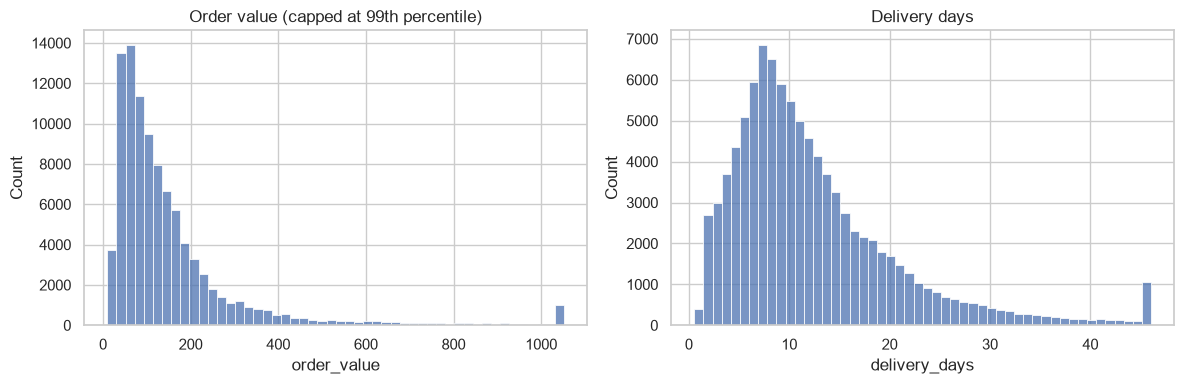

order_value      9.37
delivery_days    3.83
dtype: float64

In [73]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
v = delivered_orders["order_value"]
sns.histplot(v.clip(upper=v.quantile(0.99)), bins=50, ax=ax[0])
ax[0].set_title("Order value (capped at 99th percentile)")
d = delivered_orders["delivery_days"]
sns.histplot(d.clip(upper=d.quantile(0.99)), bins=50, ax=ax[1])
ax[1].set_title("Delivery days")
plt.tight_layout(); plt.show()

delivered_orders[["order_value", "delivery_days"]].skew().round(2)

Order value histogram-The average order value is 159.86, but the median is only 105.28, and the 99th percentile is 1,052 (skewness 9.37). Most orders are small, and a few very large orders pull the average up. The business should report median order value alongside the average, and treat high-value orders as a separate segment.

Delivery days histogram-Half of the orders arrive within 10.2 days, 90% within 23.1 days, but a long tail reaches 46 days. Most deliveries are fast, but a minority is very slow. Reducing that slow tail is where the biggest delivery gains are.

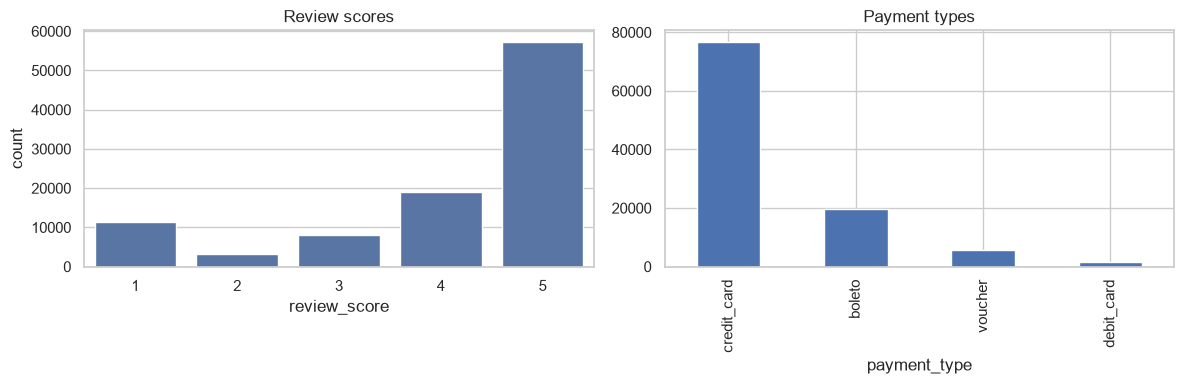

In [82]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x="review_score", data=reviews_clean, ax=ax[0]); ax[0].set_title("Review scores")
payments_clean["payment_type"].value_counts().plot.bar(ax=ax[1], title="Payment types")
plt.tight_layout(); plt.show()

Review scores-57.8% of reviews are 5 stars, but 11.5% are 1 star, far more than 2 stars (3.2%). Customers tend to be either very happy or very unhappy, with few in between. The 1-star group is where the problems are, so it should be investigated first.

Payment types-Credit cards make up 73.9% of payments, boleto 19.0%, vouchers 5.6% and debit cards 1.5%. Customers rely mostly on cards, with boleto a clear second. Payment options should prioritize cards, and boleto needs to stay supported.

 Bivariate

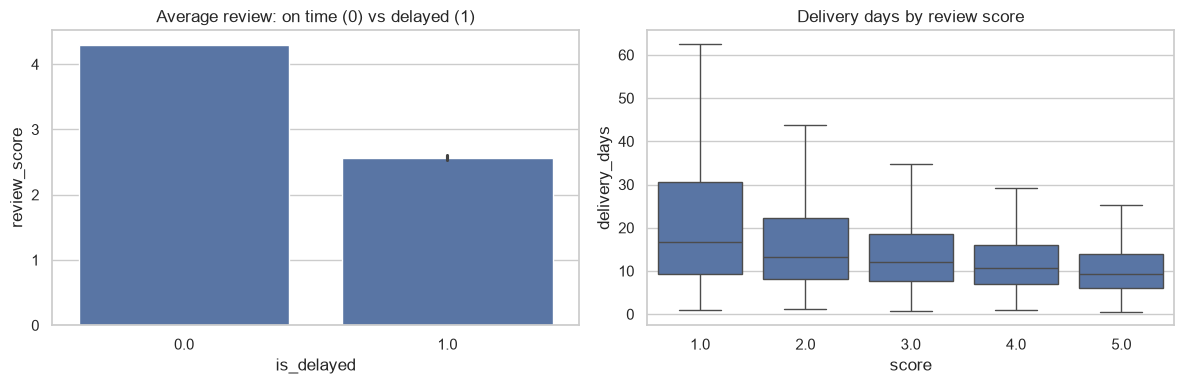

In [76]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=delivered_orders, x="is_delayed", y="review_score", ax=ax[0])
ax[0].set_title("Average review: on time (0) vs delayed (1)")

tmp = delivered_orders.assign(score=delivered_orders["review_score"].round())
sns.boxplot(data=tmp, x="score", y="delivery_days", showfliers=False, ax=ax[1])
ax[1].set_title("Delivery days by review score")
plt.tight_layout(); plt.show()

Review score: on-time vs delayed-Orders delivered on time average 4.29 stars, and delayed orders average 2.57. Delivery delays are linked to much lower satisfaction. Keeping delivery promises is likely one of the most effective ways to improve customer ratings.

Delivery days by review score-The median delivery time rises from 9.2 days for 5-star orders to 16.8 days for 1-star orders. The slower the delivery, the lower the review. Faster delivery would likely improve the share of high reviews.

Correlation

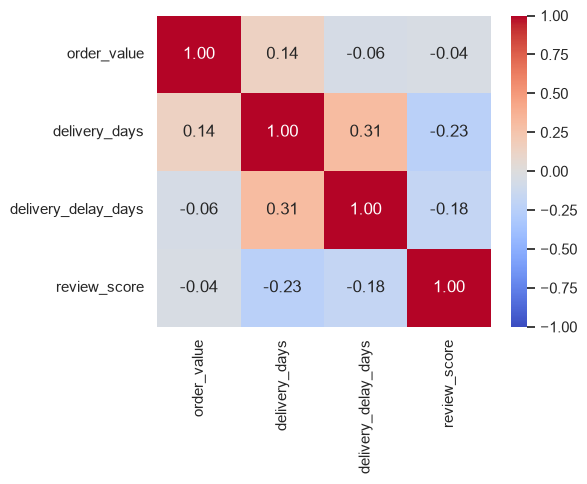

In [77]:
num = delivered_orders[["order_value", "delivery_days", "delivery_delay_days", "review_score"]]
plt.figure(figsize=(6, 5))
sns.heatmap(num.corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.tight_layout(); plt.show()

Delivery days has a moderate negative correlation with review score (−0.23), and delay has −0.18. Order value is almost unrelated to the review score (−0.04). Delivery performance matters more for satisfaction than how much a customer spends. Correlation doesn’t prove cause, so the statistical test later gives firmer evidence.

Multivariate (states)

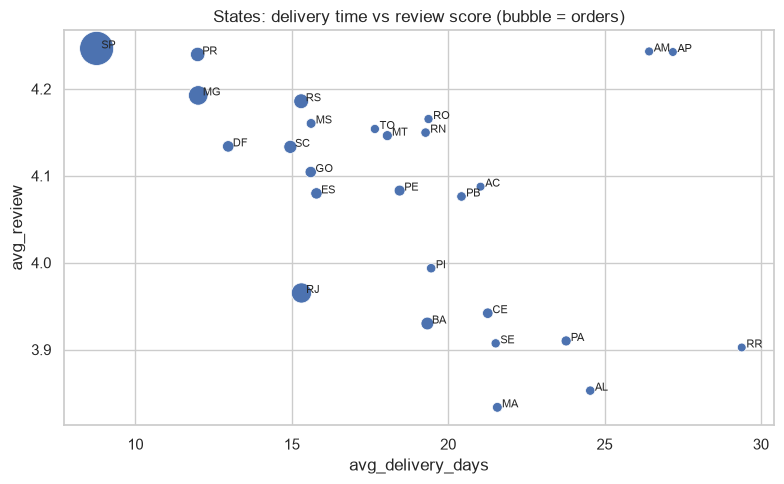

In [78]:
state = (delivered_orders.groupby("customer_state")
    .agg(orders=("order_id", "nunique"), revenue=("order_value", "sum"),
         avg_delivery_days=("delivery_days", "mean"), avg_review=("review_score", "mean"))
    .reset_index())

plt.figure(figsize=(8, 5))
sns.scatterplot(data=state, x="avg_delivery_days", y="avg_review", size="orders",
                sizes=(40, 600), legend=False)
for _, r in state.iterrows():
    plt.text(r.avg_delivery_days + 0.15, r.avg_review, r.customer_state, fontsize=8)
plt.title("States: delivery time vs review score (bubble = orders)")
plt.tight_layout(); plt.show()

São Paulo (SP) is 42% of orders and delivers in 8.8 days with a 4.25 average review, while Roraima (RR) takes 29.4 days and scores 3.90. Distant states wait much longer, and the slowest has the lowest satisfaction. Better logistics for remote states would help close the gap.

Trend and categories, from SQL

In [80]:
def run_query(sql):
    return pd.read_sql(text(sql), engine)

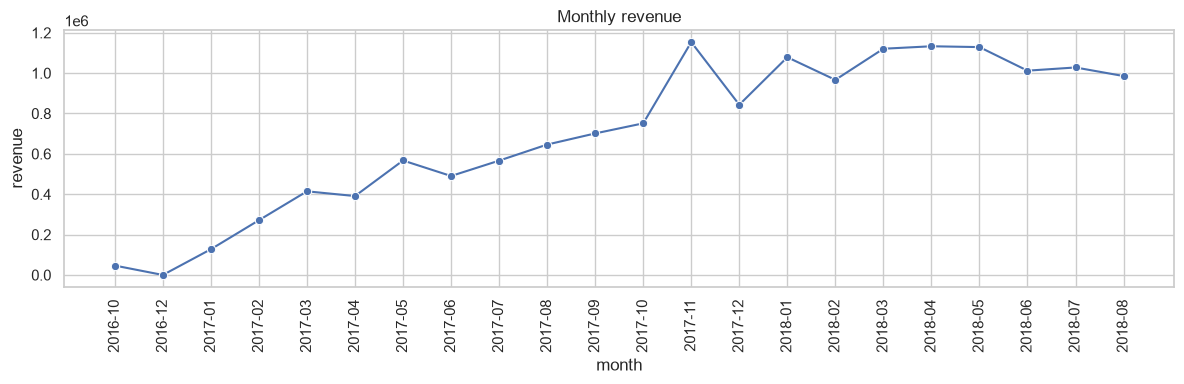

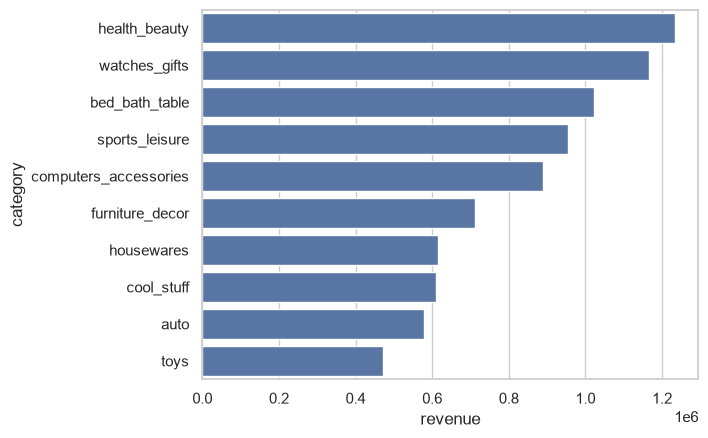

In [81]:
monthly = run_query("""
SELECT DATE_FORMAT(o.order_purchase_timestamp, '%Y-%m') AS month,
       COUNT(DISTINCT o.order_id) AS orders,
       ROUND(SUM(p.payment_value), 2) AS revenue
FROM orders o JOIN order_payments p ON o.order_id = p.order_id
WHERE o.order_status = 'delivered'
GROUP BY month ORDER BY month
""")
monthly["revenue"] = monthly["revenue"].astype(float)

plt.figure(figsize=(12, 4))
sns.lineplot(data=monthly, x="month", y="revenue", marker="o")
plt.xticks(rotation=90); plt.title("Monthly revenue"); plt.tight_layout(); plt.show()

categories = run_query("""
SELECT t.product_category_name_english AS category,
       ROUND(SUM(i.price), 2) AS revenue,
       COUNT(DISTINCT i.order_id) AS orders
FROM order_items i
JOIN orders o ON i.order_id = o.order_id
JOIN products p ON i.product_id = p.product_id
JOIN product_category_translation t ON p.product_category_name = t.product_category_name
WHERE o.order_status = 'delivered'
GROUP BY t.product_category_name_english
ORDER BY revenue DESC LIMIT 10
""")
categories["revenue"] = categories["revenue"].astype(float)
sns.barplot(data=categories, y="category", x="revenue"); plt.show()

Revenue peaked in November 2017 at about 1.15 million (7,289 orders). January to August 2018 earned 8.45 million, against 3.47 million in the same months of 2017, and it was roughly flat at about 1.0 million a month from June to August 2018. The business grew strongly, then levelled off. The November peak may be linked to seasonal sales such as Black Friday, but the data doesn’t confirm that. Planning stock and delivery capacity for the peak season would help

Top categories by revenue-Health & beauty (9.5% of revenue), watches & gifts (8.9%) and bed, bath & table (7.8%) lead, and the top 10 categories bring in 63.3% of revenue. Sales are concentrated in a small set of categories. Marketing and seller recruitment should focus on those, while the rest should be checked for growth potential.

Statistical Analysis

Test 1- T-test, delivery delay and review score

In [83]:
from scipy import stats
import numpy as np

t = order_features.dropna(subset=["is_delayed", "review_score"])
delayed = t.loc[t["is_delayed"] == 1, "review_score"]
on_time = t.loc[t["is_delayed"] == 0, "review_score"]

print("n delayed / on-time:", len(delayed), len(on_time))
print("means:", round(delayed.mean(), 3), round(on_time.mean(), 3))
print("std:", round(delayed.std(), 3), round(on_time.std(), 3))
print("skew:", round(delayed.skew(), 2), round(on_time.skew(), 2))

print("Levene (equal variances?):", stats.levene(delayed, on_time))

welch = stats.ttest_ind(delayed, on_time, equal_var=False)
print("Welch t-test:", welch.statistic, welch.pvalue)

print("Mann-Whitney check:", stats.mannwhitneyu(delayed, on_time, alternative="two-sided"))

pooled = np.sqrt(((len(delayed) - 1) * delayed.var() + (len(on_time) - 1) * on_time.var())
                 / (len(delayed) + len(on_time) - 2))
print("Cohen's d:", round((delayed.mean() - on_time.mean()) / pooled, 3))

n delayed / on-time: 7661 88163
means: 2.567 4.294
std: 1.658 1.146
skew: 0.39 -1.74
Levene (equal variances?): LeveneResult(statistic=np.float64(3387.5912133786755), pvalue=np.float64(0.0))
Welch t-test: -89.38438975067756 0.0
Mann-Whitney check: MannwhitneyuResult(statistic=np.float64(150680825.5), pvalue=np.float64(0.0))
Cohen's d: -1.446


Decision: p < 0.001 < 0.05, so we reject H0.
Delayed orders have a significantly lower mean review score (2.57 vs 4.29, a difference of about 1.7 points, Cohen's d = -1.45, a large effect).
Business insight: delivery delay has a strong negative impact on customer satisfaction. Meeting the promised delivery date
is likely one of the most effective ways to improve ratings. The test shows association, not proof of cause.

 ANOVA, product category and order value

Question: Does the average order value differ significantly across product categories?
H0: All categories have the same mean order value.
H1: At least one category has a different mean order value.
Significance level: alpha = 0.05
Test: One-way ANOVA (on log of order value)
Data: delivered orders, category of the first item in the order, the 10 largest categories.

In [85]:
import numpy as np
from scipy import stats

# category of each order = category of its first item
first_item = items_clean[items_clean["order_item_id"] == 1][["order_id", "product_id"]]
order_cat = (first_item
    .merge(products_clean[["product_id", "product_category_name"]], on="product_id")
    .merge(category_clean, on="product_category_name")
    [["order_id", "product_category_name_english"]]
    .rename(columns={"product_category_name_english": "category"}))

anova_df = (order_features[order_features["order_status"] == "delivered"]
    .merge(order_cat, on="order_id")[["order_id", "category", "order_value"]].dropna())
anova_df = anova_df[anova_df["order_value"] > 0]

top = anova_df["category"].value_counts().head(10).index
anova_df = anova_df[anova_df["category"].isin(top)].copy()
anova_df["log_value"] = np.log(anova_df["order_value"])

print(anova_df.groupby("category")["order_value"].agg(["count", "mean", "median"])
      .round(2).sort_values("mean"))

groups = [g["log_value"].values for _, g in anova_df.groupby("category")]
print("skew raw / log:", round(anova_df["order_value"].skew(), 2), round(anova_df["log_value"].skew(), 2))
print("Levene:", stats.levene(*groups))
print("ANOVA:", stats.f_oneway(*groups))
print("Kruskal-Wallis check:", stats.kruskal(*groups))

grand = anova_df["log_value"].mean()
ss_between = sum(len(g) * (g.mean() - grand) ** 2 for g in groups)
ss_total = ((anova_df["log_value"] - grand) ** 2).sum()
print("eta squared:", round(ss_between / ss_total, 3))

                       count    mean  median
category                                    
telephony               4076   93.13   45.22
bed_bath_table          9167  133.58  105.54
housewares              5688  133.75   88.73
furniture_decor         6213  142.31  104.64
toys                    3779  144.65  104.03
sports_leisure          7491  149.43  110.90
computers_accessories   6501  158.57  103.13
health_beauty           8607  163.92  104.12
auto                    3793  176.48  111.42
watches_gifts           5472  230.62  158.52
skew raw / log: 6.7 0.5
Levene: LeveneResult(statistic=np.float64(114.95106473429226), pvalue=np.float64(4.4529313775199336e-215))
ANOVA: F_onewayResult(statistic=np.float64(476.9763808490804), pvalue=np.float64(0.0))
Kruskal-Wallis check: KruskalResult(statistic=np.float64(4312.718452027056), pvalue=np.float64(0.0))
eta squared: 0.066


Chi-square, payment method and order status

In [86]:
import numpy as np
from scipy import stats

# one payment method per order: the first payment
main_payment = (payments_clean.sort_values(["order_id", "payment_sequential"])
                .drop_duplicates("order_id")[["order_id", "payment_type"]])
chi_df = orders_clean[["order_id", "order_status"]].merge(main_payment, on="order_id")

# check the assumption BEFORE grouping
raw_ct = pd.crosstab(chi_df["payment_type"], chi_df["order_status"])
_, _, _, exp = stats.chi2_contingency(raw_ct)
print("cells with expected count < 5:", int((exp < 5).sum()), "of", exp.size)

# combine the very rare statuses into "other"
chi_df["status_group"] = chi_df["order_status"].where(
    chi_df["order_status"].isin(["delivered", "shipped", "canceled", "unavailable"]), "other")
ct = pd.crosstab(chi_df["payment_type"], chi_df["status_group"])
print(ct)

chi2, p, dof, expected = stats.chi2_contingency(ct)
print("chi2:", round(chi2, 2), "| dof:", dof, "| p:", p)
print("smallest expected count:", round(expected.min(), 2))

n = ct.values.sum()
print("Cramer's V:", round(np.sqrt(chi2 / (n * (min(ct.shape) - 1))), 3))

(pd.crosstab(chi_df["payment_type"], chi_df["status_group"], normalize="index") * 100).round(2)

cells with expected count < 5: 11 of 32
status_group  canceled  delivered  other  shipped  unavailable
payment_type                                                  
boleto              95      19191    139      209          150
credit_card        444      74303    466      848          443
debit_card           7       1485      8       22            6
voucher             76       1498      9       28           10
chi2: 460.87 | dof: 12 | p: 4.6371913951317925e-91
smallest expected count: 9.36
Cramer's V: 0.039


status_group,canceled,delivered,other,shipped,unavailable
payment_type,,,,,
boleto,0.48,97.00,0.70,1.06,0.76
credit_card,0.58,97.12,0.61,1.11,0.58
debit_card,0.46,97.19,0.52,1.44,0.39
voucher,4.69,92.41,0.56,1.73,0.62


In [87]:
python -m streamlit run streamlit/app.py

SyntaxError: invalid syntax (1251598710.py, line 1)